# UCS420 — Cognitive Computing | Assignment 7

**Name:** Aanya Garg  
**Roll Number:** 1024170172

This notebook uses a function-based workflow and a separately maintained original/discounted sales table. The calculations are reproducible because the random generator is initialized with the roll number.

## Q1. Monthly sales data using NumPy and Pandas

Generate 12 months of sales for four product categories. The generated values range from 1,000 to 5,000 (inclusive).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROLL_NUMBER = 1024170172
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
PRODUCTS = ["Electronics", "Clothing", "Home & Kitchen", "Sports"]

# A dedicated generator keeps this notebook's random sequence reproducible.
rng = np.random.default_rng(ROLL_NUMBER)
sales_values = rng.integers(1000, 5001, size=(len(MONTHS), len(PRODUCTS)))

sales = pd.DataFrame(sales_values, index=MONTHS, columns=PRODUCTS)
sales.index.name = "Month"
print("Roll number:", ROLL_NUMBER)
print("Generated data shape:", sales.shape)
display(sales)

Roll number: 1024170172
Generated data shape: (12, 4)


,Electronics,Clothing,Home & Kitchen,Sports
Month,,,,
Jan,1093,3241,1755,4155
Feb,4172,3576,2873,2938
Mar,2216,4912,4296,3003
Apr,4220,1472,2660,3405
May,2708,1753,1808,2053
Jun,2327,3281,1875,1648
Jul,3619,3739,4912,2746
Aug,3835,4607,4301,3321
Sep,2393,2991,2223,4543


### Data inspection and summary

Check the first five records, descriptive statistics, and whether the generated data contains missing values.

In [2]:
print("First five months:")
display(sales.head())

print("Descriptive statistics:")
display(sales.describe().round(2))

print("Missing values in the dataset:", int(sales.isna().sum().sum()))
print("Minimum and maximum generated sales:", int(sales.min().min()), "and", int(sales.max().max()))

First five months:


,Electronics,Clothing,Home & Kitchen,Sports
Month,,,,
Jan,1093,3241,1755,4155
Feb,4172,3576,2873,2938
Mar,2216,4912,4296,3003
Apr,4220,1472,2660,3405
May,2708,1753,1808,2053


Descriptive statistics:


,Electronics,Clothing,Home & Kitchen,Sports
count,12.00,12.00,12.00,12.00
mean,2767.33,2939.17,2963.83,2826.33
std,1184.23,1196.69,1201.65,1095.06
min,1093.00,1412.00,1449.00,1000.00
25%,1999.50,1706.50,1858.25,1951.75
50%,2550.50,3116.00,2766.50,2970.50
75%,3888.75,3616.75,4227.00,3464.25
max,4220.00,4912.00,4912.00,4543.00


Missing values in the dataset: 0
Minimum and maximum generated sales: 1000 and 4912


### Total sales by product and by month

In [3]:
product_totals = sales.sum()
monthly_totals = sales.sum(axis=1)

print("Total sales for each product:")
display(product_totals.rename("Total units").to_frame())

print("Total sales for each month:")
display(monthly_totals.rename("Total units").to_frame())

print("Highest-selling product:", product_totals.idxmax())
print("Highest-selling month:", monthly_totals.idxmax())

Total sales for each product:


,Total units
Electronics,33208
Clothing,35270
Home & Kitchen,35566
Sports,33916


Total sales for each month:


,Total units
Month,
Jan,10244
Feb,13559
Mar,14427
Apr,11757
May,8322
Jun,9131
Jul,15016
Aug,16064
Sep,12150


Highest-selling product: Home & Kitchen
Highest-selling month: Aug


### Average month-to-month growth

Show two measures for each product:
- **Change in units:** the average difference between consecutive months.
- **Percentage growth:** the average percentage change from one month to the next.

The first month is excluded because it has no preceding month for comparison.

In [4]:
# Calculate month-to-month change in both units and percentage terms.
monthly_change_units = sales.diff().mean().rename("Average monthly change (units)")
growth_by_product = sales.pct_change(fill_method=None).mul(100)
average_growth = growth_by_product.mean().rename("Average monthly growth (%)")

print("Average month-to-month change in units:")
display(monthly_change_units.to_frame().round(2))

print("Average month-to-month percentage growth:")
display(average_growth.to_frame().round(2))

Average month-to-month change in units:


,Average monthly change (units)
Electronics,12.00
Clothing,-152.18
Home & Kitchen,-27.82
Sports,-244.82


Average month-to-month percentage growth:


,Average monthly growth (%)
Electronics,35.08
Clothing,7.58
Home & Kitchen,14.35
Sports,0.46


### Add monthly total and overall growth rate

In [5]:
sales_analysis = sales.copy()
sales_analysis["Total Sales"] = sales.sum(axis=1)
sales_analysis["Growth Rate (%)"] = sales_analysis["Total Sales"].pct_change(fill_method=None) * 100
print("Monthly sales with combined total and growth rate:")
display(sales_analysis.round(2))

Monthly sales with combined total and growth rate:


,Electronics,Clothing,Home & Kitchen,Sports,Total Sales,Growth Rate (%)
Month,,,,,,
Jan,1093,3241,1755,4155,10244,NaN
Feb,4172,3576,2873,2938,13559,32.36
Mar,2216,4912,4296,3003,14427,6.40
Apr,4220,1472,2660,3405,11757,-18.51
May,2708,1753,1808,2053,8322,-29.22
Jun,2327,3281,1875,1648,9131,9.72
Jul,3619,3739,4912,2746,15016,64.45
Aug,3835,4607,4301,3321,16064,6.98
Sep,2393,2991,2223,4543,12150,-24.37


### Apply the roll-number-based discount

The roll number is **even**, so apply a **10% discount to Electronics**. Keep the original data unchanged and create a separate adjusted table for comparison.

In [6]:
discounted_sales = sales.copy()
if ROLL_NUMBER % 2 == 0:
    discount_product = "Electronics"
    discount_rate = 0.10
else:
    discount_product = "Clothing"
    discount_rate = 0.15

discounted_sales[discount_product] *= (1 - discount_rate)
discounted_sales["Revised Monthly Total"] = discounted_sales[PRODUCTS].sum(axis=1)
discounted_sales["Amount Reduced"] = sales[discount_product] * discount_rate

print(f"{discount_rate:.0%} discount applied to {discount_product}.")
display(discounted_sales.round(2))
print("Original annual total:", round(sales[PRODUCTS].to_numpy().sum(), 2))
print("Adjusted annual total:", round(discounted_sales["Revised Monthly Total"].sum(), 2))

10% discount applied to Electronics.


,Electronics,Clothing,Home & Kitchen,Sports,Revised Monthly Total,Amount Reduced
Month,,,,,,
Jan,983.7,3241,1755,4155,10134.7,109.3
Feb,3754.8,3576,2873,2938,13141.8,417.2
Mar,1994.4,4912,4296,3003,14205.4,221.6
Apr,3798.0,1472,2660,3405,11335.0,422.0
May,2437.2,1753,1808,2053,8051.2,270.8
Jun,2094.3,3281,1875,1648,8898.3,232.7
Jul,3257.1,3739,4912,2746,14654.1,361.9
Aug,3451.5,4607,4301,3321,15680.5,383.5
Sep,2153.7,2991,2223,4543,11910.7,239.3


Original annual total: 137960
Adjusted annual total: 134639.2


## Q1 — Visual representation

The first chart compares monthly movement across products. The second compares the spread of monthly sales values for each product.

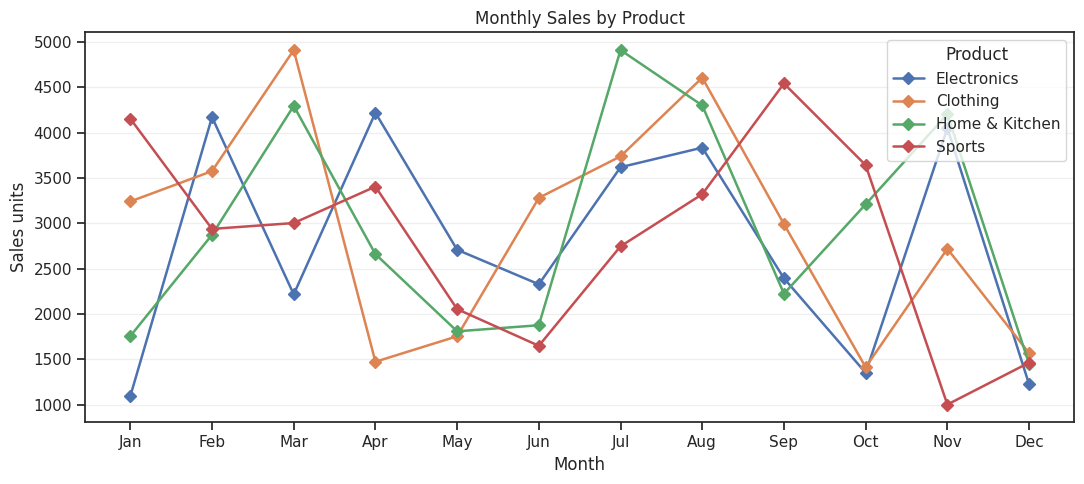

In [7]:
sns.set_theme(style="ticks")
fig, ax = plt.subplots(figsize=(11, 5))
for product in PRODUCTS:
    ax.plot(sales.index, sales[product], marker="D", linewidth=1.8, label=product)
ax.set(title="Monthly Sales by Product", xlabel="Month", ylabel="Sales units")
ax.legend(title="Product")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

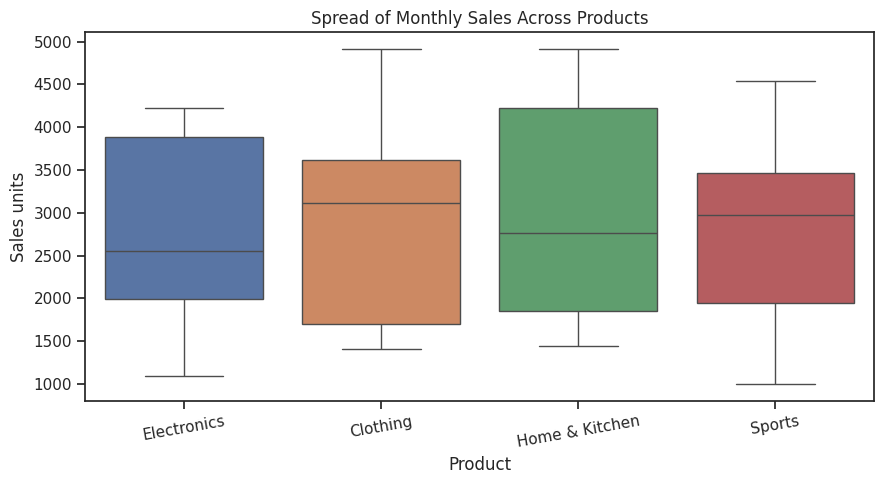

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=sales, orient="v", ax=ax)
ax.set(title="Spread of Monthly Sales Across Products", xlabel="Product", ylabel="Sales units")
ax.tick_params(axis="x", rotation=10)
fig.tight_layout()
plt.show()

## Q2. NumPy array calculations

For the given 2 × 3 array, calculate absolute values, the 25th/50th/75th percentiles, and mean, median and standard deviation for the flattened array, columns and rows.

In [9]:
values = np.array([[1, -2, 3], [-4, 5, -6]])
print("Input array:\n", values)
print("\nAbsolute values:\n", np.abs(values))

percentile_levels = [25, 50, 75]
for label, axis in [("Entire array", None), ("Column-wise", 0), ("Row-wise", 1)]:
    result = np.percentile(values, percentile_levels, axis=axis)
    print(f"\n{label} percentiles (25, 50, 75):\n{result}")

for label, data, axis in [("Entire array", values, None),
                          ("Column-wise", values, 0),
                          ("Row-wise", values, 1)]:
    print(f"\n{label} statistics:")
    print("Mean:", np.mean(data, axis=axis))
    print("Median:", np.median(data, axis=axis))
    print("Standard deviation:", np.std(data, axis=axis))

Input array:
 [[ 1 -2  3]
 [-4  5 -6]]

Absolute values:
 [[1 2 3]
 [4 5 6]]

Entire array percentiles (25, 50, 75):
[-3.5 -0.5  2.5]

Column-wise percentiles (25, 50, 75):
[[-2.75 -0.25 -3.75]
 [-1.5   1.5  -1.5 ]
 [-0.25  3.25  0.75]]

Row-wise percentiles (25, 50, 75):
[[-0.5 -5. ]
 [ 1.  -4. ]
 [ 2.   0.5]]

Entire array statistics:
Mean: -0.5
Median: -0.5
Standard deviation: 3.8622100754188224

Column-wise statistics:
Mean: [-1.5  1.5 -1.5]
Median: [-1.5  1.5 -1.5]
Standard deviation: [2.5 3.5 4.5]

Row-wise statistics:
Mean: [ 0.66666667 -1.66666667]
Median: [ 1. -4.]
Standard deviation: [2.05480467 4.78423336]


## Q3. Floor, ceiling, truncation and rounding

Apply the four NumPy operations to every value in the supplied array.

In [10]:
decimal_values = np.array([-1.8, -1.6, -0.5, 0.5, 1.6, 1.8, 3.0])
rounding_table = pd.DataFrame({
    "Original": decimal_values,
    "Floor": np.floor(decimal_values),
    "Ceiling": np.ceil(decimal_values),
    "Truncate": np.trunc(decimal_values),
    "Round": np.round(decimal_values)
})
display(rounding_table)

,Original,Floor,Ceiling,Truncate,Round
0,-1.8,-2.0,-1.0,-1.0,-2.0
1,-1.6,-2.0,-1.0,-1.0,-2.0
2,-0.5,-1.0,-0.0,-0.0,-0.0
3,0.5,0.0,1.0,0.0,0.0
4,1.6,1.0,2.0,1.0,2.0
5,1.8,1.0,2.0,1.0,2.0
6,3.0,3.0,3.0,3.0,3.0


## Q4. Swap two elements in a list

Use a temporary variable to exchange the elements at two selected positions.

In [11]:
def swap_list_positions(data, position_a, position_b):
    if not (0 <= position_a < len(data) and 0 <= position_b < len(data)):
        raise IndexError("Position is outside the list")
    saved_value = data[position_a]
    data[position_a] = data[position_b]
    data[position_b] = saved_value
    return data

sample_list = ["red", "blue", "green", "yellow", "purple"]
print("Before:", sample_list)
swap_list_positions(sample_list, 1, 3)
print("After swapping positions 1 and 3:", sample_list)

Before: ['red', 'blue', 'green', 'yellow', 'purple']
After swapping positions 1 and 3: ['red', 'yellow', 'green', 'blue', 'purple']


## Q5. Swap set elements by converting the set to a list

A set has no positional order. Sorting it first makes the demonstration repeatable. The list shows the swapped positions; converting it back to a set preserves membership, not order.

In [12]:
def swap_set_members_via_list(original_set, position_a, position_b):
    ordered_items = sorted(original_set)
    if not (0 <= position_a < len(ordered_items) and 0 <= position_b < len(ordered_items)):
        raise IndexError("Position is outside the converted list")
    ordered_items[position_a], ordered_items[position_b] = ordered_items[position_b], ordered_items[position_a]
    return ordered_items, set(ordered_items)

sample_set = {12, 24, 36, 48, 60}
print("Original set:", sample_set)
swapped_list, resulting_set = swap_set_members_via_list(sample_set, 0, 2)
print("List after swapping positions 0 and 2:", swapped_list)
print("Set after converting back:", resulting_set)

Original set: {48, 36, 24, 12, 60}
List after swapping positions 0 and 2: [36, 24, 12, 48, 60]
Set after converting back: {36, 12, 48, 24, 60}
